In [194]:
pip install corner

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
from hdbscan import HDBSCAN
import seaborn as sns

from datetime import datetime, timedelta
from astropy.time import Time

import corner

In [2]:
deltat = 0.2         # time btw triggers from the same cluster 

min_triggers = 40
SNRvalue_cut = 7.5
gap_time = 2.0        # time btw possible duplicated glitches
threshold_snr = 1.0

In [44]:
run = 'O3a'
clust = 'groupGreen'
arqType = "non_matched_gdchar"

base = "/home/esanches/Projetos/tSNE/Virgo"
repository = "/home/esanches/Projetos/tSNE/Virgo/zrepository"
save_file = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + clust + "/" + run

suffix = "_C" + str(min_triggers) + "_dT" + str(deltat) + "_SNR" + str(SNRvalue_cut) + "_gt" + str(gap_time) + "_th" + str(threshold_snr)

In [45]:
save_file

'/home/esanches/Projetos/tSNE/Virgo/zrepository/groupGreen/O3a'

## Functions

In [5]:
def create_glitchgram(unclustered, clustered, deltat, fmin=3, fmax=8192, tbins=41, fbins=30):
    
    all_glitchgrams = []
    rel_times = []
    center_freqs = []

    unclustered = unclustered.sort_values("time")
    
    times_all = unclustered['time'].values
    freqs_all = unclustered['frequency'].values
    snrs_all  = unclustered['snr'].values

    time_edges = np.linspace(-deltat/2, deltat/2, tbins+1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins+1)
    
    for i, row in enumerate(clustered.itertuples(index=False)):

        t_center = row.time
        f_center = row.frequency
        
        tmin = t_center - deltat/2
        tmax = t_center + deltat/2
    
        i0 = np.searchsorted(times_all, tmin, side="left")
        i1 = np.searchsorted(times_all, tmax, side="right")
    
        times = times_all[i0:i1] - t_center
        freqs = freqs_all[i0:i1]
        snrs  = snrs_all[i0:i1]

        t_idx = np.digitize(times, time_edges) - 1
        f_idx = np.digitize(freqs, freq_edges) - 1
            
        # initial empty matrix
        A = np.zeros((fbins, tbins), dtype=float)
    
        for ti, fi, si in zip(t_idx, f_idx, snrs):
            if 0 <= ti < tbins and 0 <= fi < fbins:
                if si > A[fi, ti]:
                    A[fi, ti] = si
                    
        '''# normalização do SNR 
        if len(snrs) > 0:
            snr_min = snrs.min()
            snr_max = snrs.max()
            if snr_max > snr_min:
                norm_snrs = (snrs - snr_min) / (snr_max - snr_min)
            else:
                norm_snrs = np.zeros_like(snrs)
        else:
            norm_snrs = snrs'''

        all_glitchgrams.append(A)
        rel_times.append(t_center)
        center_freqs.append(f_center)
    
    return all_glitchgrams, rel_times, center_freqs

In [6]:
def plot_grid2(arr, times, freqs, title, max_plots=None, t_min=-1.0, t_max=1.0, f_min=10, f_max=1024):

    n_total = len(arr)
    if n_total == 0:
        print(f"Nenhum glitch encontrado em {title}")
        return

    # Limita a quantidade N de plots se max_plots for informado
    if max_plots is not None and max_plots > 0:
        arr = arr[:max_plots]
        times = times[:max_plots]
        freqs = freqs[:max_plots]
    
    n = len(arr)
    
    cols = 5
    rows = int(np.ceil(n / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.0, rows * 2.5))
    axes = np.atleast_1d(axes).flatten()
    
    # Exibe o total plotado em relação ao total existente no título
    fig.suptitle(f"{title} (Exibindo {n} de {n_total})", fontsize=12, fontweight='bold', y=1.02)
    
    # Define as marcas do grid a cada 0.1s
    time_ticks = np.arange(t_min, t_max + 0.1, 0.1)
    
    for i in range(n):
        # O 'extent' mapeia os pixels da matriz para as coordenadas reais [t_min, t_max, f_min, f_max]
        axes[i].imshow(arr[i], origin='lower', aspect='auto', extent=[t_min, t_max, f_min, f_max])

        # Configura as marcas do eixo X a cada 0.1s
        axes[i].set_xticks(time_ticks)
        
        # Adiciona a grade tracejada com transparência
        axes[i].grid(True, which='both', color='white', linestyle='--', linewidth=0.5, alpha=0.5)
        
        # Esconde os números das eixos para não poluir, mantendo apenas as linhas do grid
        axes[i].set_xticklabels([])
        axes[i].set_yticklabels([])
        
        # Remove os risquinhos dos eixos (ticks) deixando só as linhas de grade na imagem
        axes[i].tick_params(left=False, bottom=False)

        t_short = str(int(times[i]))[-7:]
        f_val = freqs[i]
        
        axes[i].set_title(f"#{i} - {t_short} - {f_val:.0f}", fontsize=9, pad=4)
        
    # Desativa os subplots vazios sobrantes na grade
    for j in range(n, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
    plt.close()

## Triggers

In [9]:
trigcols = ['time', 'frequency', 'snr']

dtypes = {
    'time': 'float64',
    'frequency': 'float32',
    'snr': 'float32'
}

path = base + "/" + "triggers_total_" + run + ".csv"

chunk_size = 10_000_000
count = 0
chunks = []

for chunk in pd.read_csv(path, usecols=trigcols, dtype=dtypes, chunksize=chunk_size):
    print(f'Reading chunk: {count}')
    chunks.append(chunk)
    count += 1

triggers = pd.concat(chunks, ignore_index=True)
triggers = triggers.sort_values('time').reset_index(drop=True)

unclustered_all = triggers.copy()

Reading chunk: 0
Reading chunk: 1
Reading chunk: 2
Reading chunk: 3
Reading chunk: 4
Reading chunk: 5
Reading chunk: 6
Reading chunk: 7
Reading chunk: 8
Reading chunk: 9
Reading chunk: 10
Reading chunk: 11
Reading chunk: 12
Reading chunk: 13
Reading chunk: 14
Reading chunk: 15


## tSNE and HDBSCAN* for Matched

In [40]:
sps = 6991
perp = 30

final_vecs = np.load(save_file + "/vecs_" + arqType + str(sps) + ".npy")
final_labs = np.load(save_file + "/labs_" + arqType + str(sps) + ".npy")

In [41]:
tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)

le = LabelEncoder()
labels = le.fit_transform(final_labs.ravel())

proj = tsne.fit_transform(final_vecs)

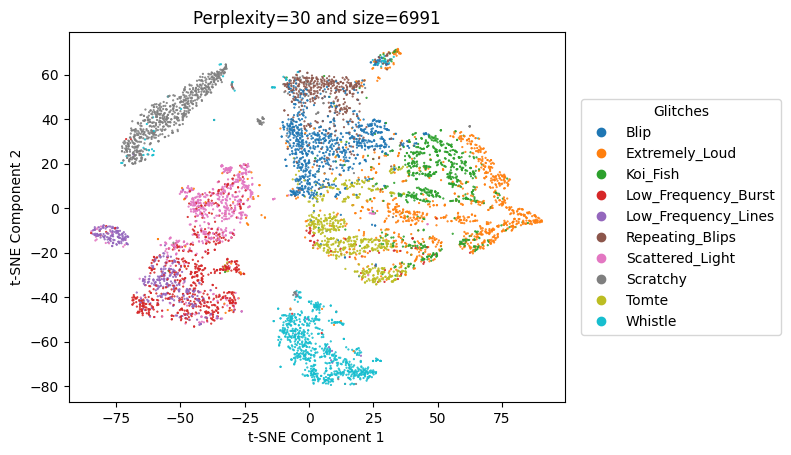

In [43]:
sc = plt.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")

plt.title(f"Perplexity={perp} and size={len(proj)}", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), 
          title="Glitches", loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.show()

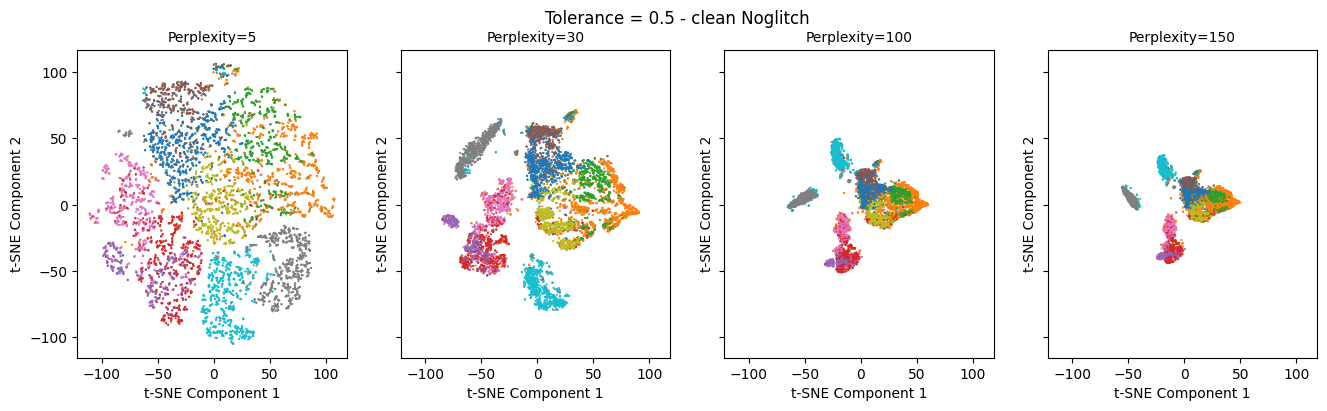

In [39]:
perplexities = [5, 30, 100, 150]

fig, axs = plt.subplots(1, len(perplexities), figsize=(4 * len(perplexities), 4), sharex=True, sharey=True)

for i, perp in enumerate(perplexities):

    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
    proj = tsne.fit_transform(final_vecs)

    ax = axs[i]
    
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")
    
    ax.set_title(f"Perplexity={perp}", fontsize=10)
    ax.set_xlabel("t-SNE Component 1", fontsize=10)
    ax.set_ylabel("t-SNE Component 2", fontsize=10)

fig.suptitle(f"Tolerance = 0.5 - clean Noglitch", fontsize=12)

plt.show()

### HDBSCAN*

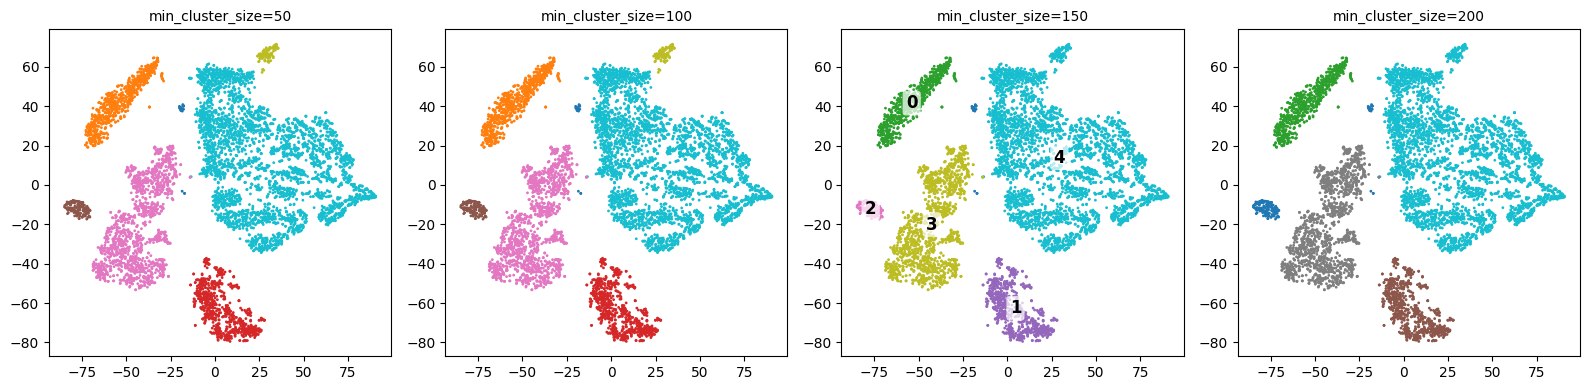

In [14]:
sizes = [50, 100, 150, 200]

perp  = 30

fig, axs = plt.subplots(1, len(sizes), figsize=(len(sizes)*4, 4))

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

for i, s in enumerate(sizes):
    hdbscan_labels = HDBSCAN(min_cluster_size=s, min_samples=5).fit_predict(proj)

    axs[i].scatter(*proj.T, c=hdbscan_labels, cmap='tab10', s=1)
    axs[i].set_title(f'min_cluster_size={s}', fontsize=10)

    if s == 150:
        unique_labels = np.unique(hdbscan_labels)
        clusters_validos = [lbl for lbl in unique_labels if lbl >= 0]
        
        for lbl in clusters_validos:
            pontos_cluster = proj[hdbscan_labels == lbl]
            
            centroide_x = np.mean(pontos_cluster[:, 0])
            centroide_y = np.mean(pontos_cluster[:, 1])
            
            axs[i].text(
                centroide_x, centroide_y, str(lbl),
                fontsize=12, fontweight='bold', color='black',
                ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
            )
            
plt.tight_layout()
plt.show()

escolhemos visualmente que min_cluster_size=150 gera a melhor distribuição. Precisamos elaborar uma forma de escolher isso automaticamente.

### Correspondence Matrix

In [15]:
hdbscan_labels = HDBSCAN(min_cluster_size=150, min_samples=5).fit_predict(proj)

df_compare = pd.DataFrame({'GravitySpy': final_labs, 'HDBSCAN': hdbscan_labels})
mask = (df_compare['HDBSCAN'] != -1)
df_compare_off_noise = df_compare[mask]

matriz_normalizada = pd.crosstab(df_compare_off_noise['GravitySpy'], df_compare_off_noise['HDBSCAN'], normalize='index') * 100

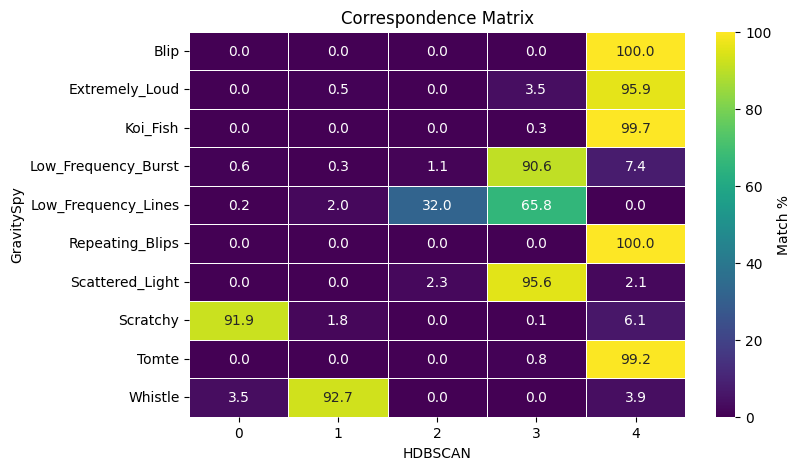

In [16]:
plt.figure(figsize=(8, 5))

sns.heatmap(matriz_normalizada, annot=True, cmap='viridis', fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Match %'})

plt.title('Correspondence Matrix', fontsize=12)

plt.show()

## tSNE and HDBSCAN* for nonMatched_Gdchar

In [53]:
sps = 20274
perp = 30

final_vecs = np.load(save_file + "/vecs" + "_" + arqType + f"{sps}" + ".npy")
final_GPSs = np.load(save_file + "/GPSs" + "_" + arqType + f"{sps}" + ".npy")

GSParray = np.array(final_GPSs)
indices = np.argsort(GSParray)
final_vecs = final_vecs[indices]
final_GPSs = final_GPSs[indices]

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

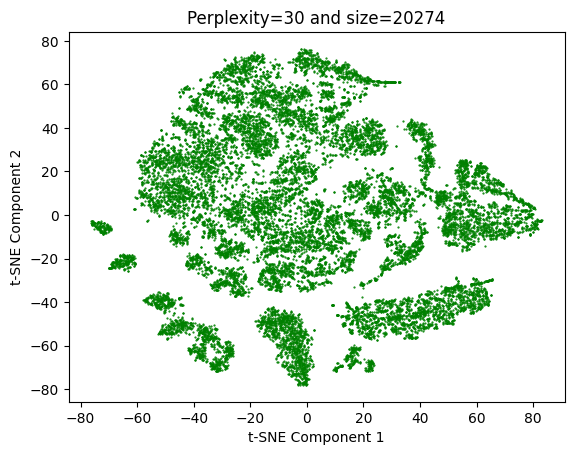

In [54]:
sc = plt.scatter(proj[:, 0], proj[:, 1], c='green', s=0.3)

plt.title(f"Perplexity={perp} and size={len(proj)}", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.show()

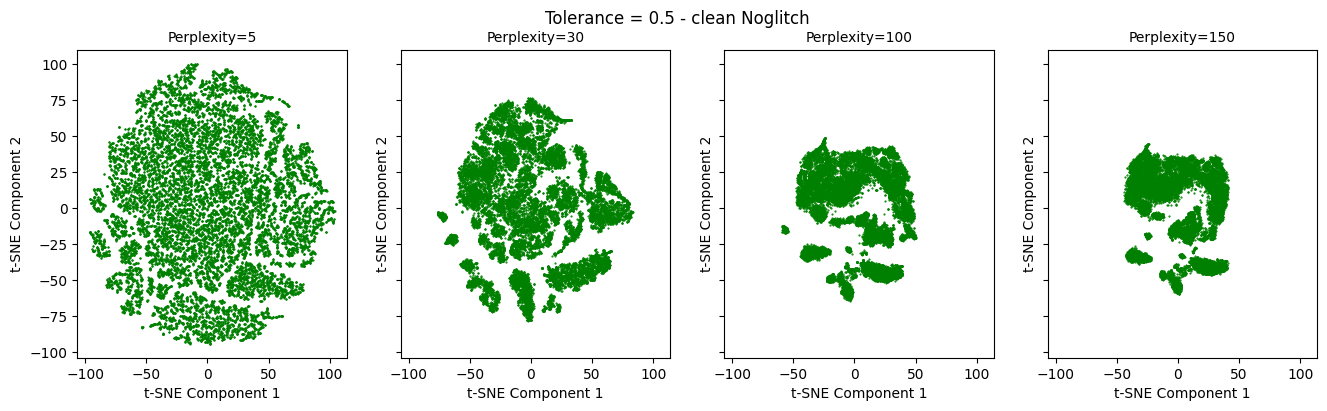

In [56]:
perplexities = [5, 30, 100, 150]

fig, axs = plt.subplots(1, len(perplexities), figsize=(4 * len(perplexities), 4), sharex=True, sharey=True)

for i, perp in enumerate(perplexities):

    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
    proj = tsne.fit_transform(final_vecs)

    ax = axs[i]
    
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c='green')
    
    ax.set_title(f"Perplexity={perp}", fontsize=10)
    ax.set_xlabel("t-SNE Component 1", fontsize=10)
    ax.set_ylabel("t-SNE Component 2", fontsize=10)

fig.suptitle(f"Tolerance = 0.5 - clean Noglitch", fontsize=12)

plt.show()

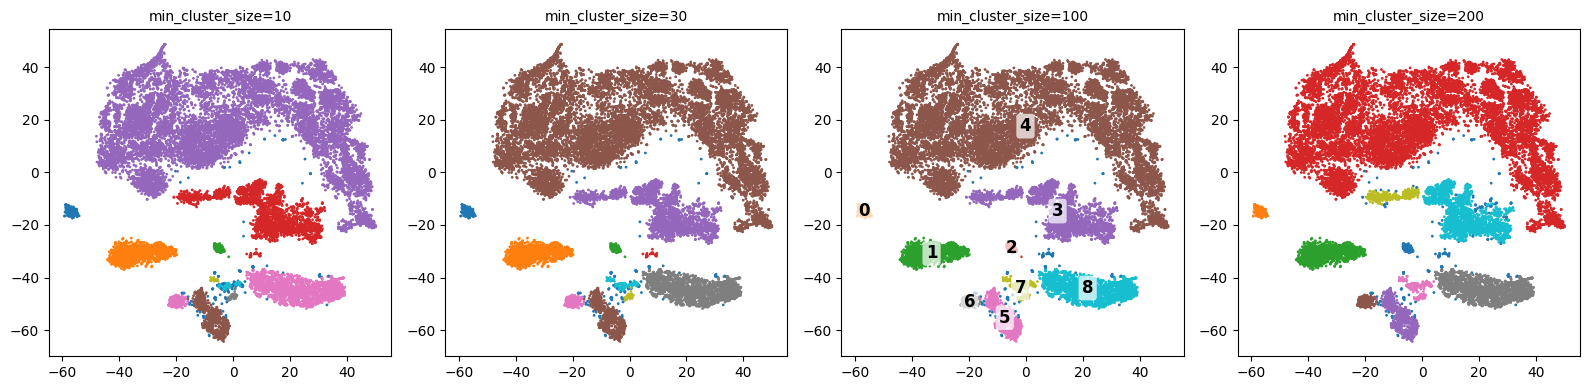

In [59]:
sizes = [10, 30, 100, 200]

perp  = 100

fig, axs = plt.subplots(1, len(sizes), figsize=(len(sizes)*4, 4))

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

for i, s in enumerate(sizes):
    hdbscan_labels = HDBSCAN(min_cluster_size=s, min_samples=20).fit_predict(proj)

    axs[i].scatter(*proj.T, c=hdbscan_labels, cmap='tab10', s=1)
    axs[i].set_title(f'min_cluster_size={s}', fontsize=10)

    if s == 100:
        unique_labels = np.unique(hdbscan_labels)
        clusters_validos = [lbl for lbl in unique_labels if lbl >= 0]
        
        for lbl in clusters_validos:
            pontos_cluster = proj[hdbscan_labels == lbl]
            
            centroide_x = np.mean(pontos_cluster[:, 0])
            centroide_y = np.mean(pontos_cluster[:, 1])
            
            axs[i].text(
                centroide_x, centroide_y, str(lbl),
                fontsize=12, fontweight='bold', color='black',
                ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
            )
            
plt.tight_layout()
plt.show()

### Non-matched_gdchar Glithcgrams

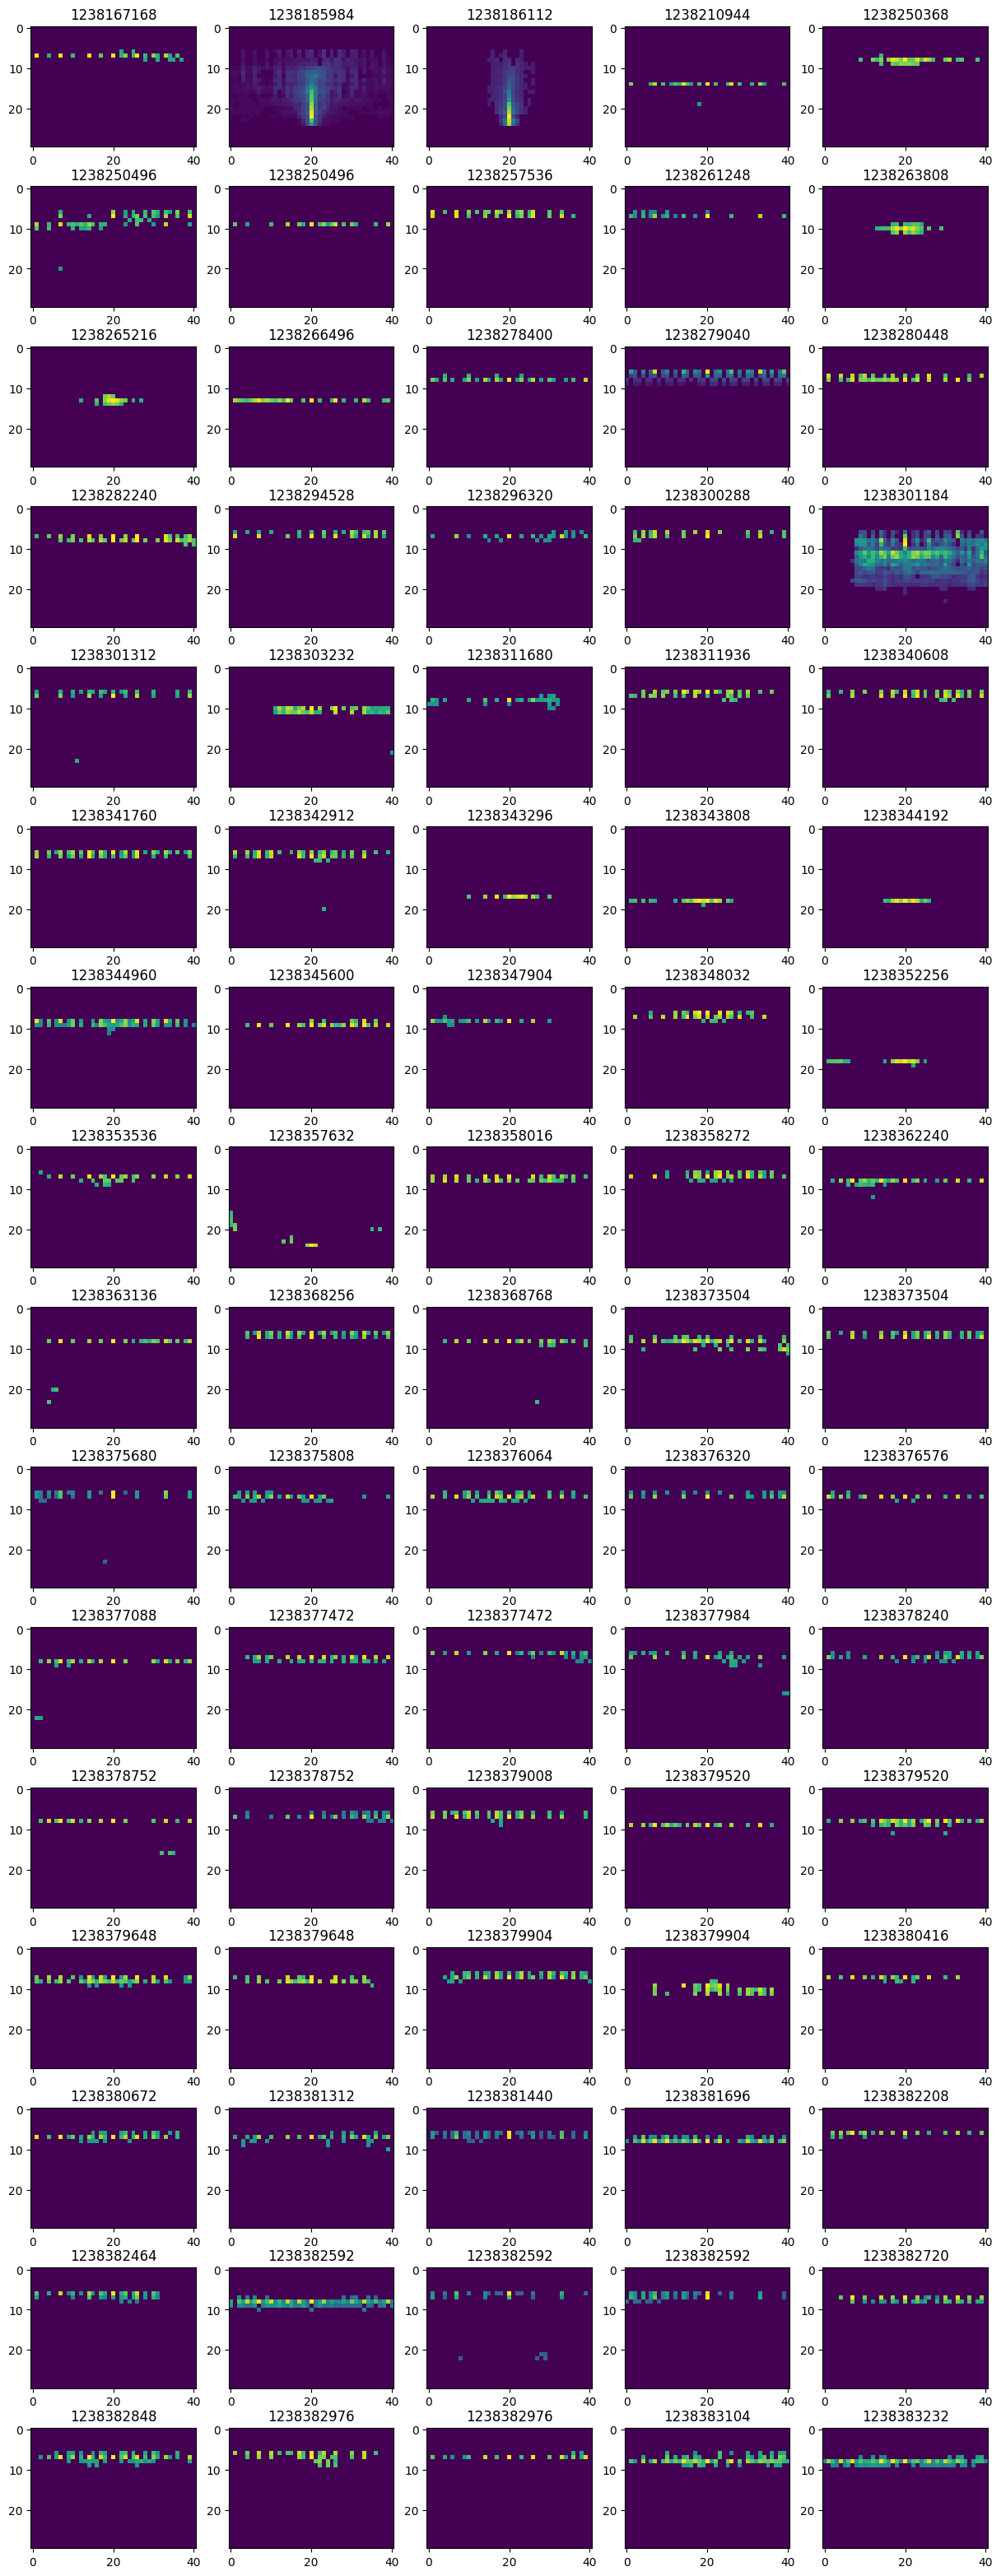

In [29]:
fig, axs = plt.subplots(16, 5, figsize=(15, 40))
axs = axs.flatten()

for i in range(80):

    ax = axs[i]
    time = final_GPSs[i]
    
    glitchgram = final_vecs[i].reshape(30, 41)
    ax.imshow(glitchgram)
    ax.set_title(f'{time:.0f}')
    
plt.show()

comparar com os glitches do GSPY no mesmo intervalo

In [351]:
filterr = True
suffix = "_filtered" if filterr else "_"

In [353]:
vecs_path = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + 'gspy' + "/" + run + "/" + "vecs" + suffix + ".npy"
labs_path = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + 'gspy' + "/" + run + "/" + "labs" + suffix + ".npy"
GPSs_path = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + 'gspy' + "/" + run + "/" + "GPSs" + suffix + ".npy"

final_vecs = np.load(vecs_path)
final_labs = np.load(labs_path)

FileNotFoundError: [Errno 2] No such file or directory: '/home/esanches/Projetos/tSNE/Virgo/zrepository/gspy/O3a/vecs_filtered.npy'

In [309]:
save_file + "/vecs" + suffix + "_" + arqType + ".npy"

'/home/esanches/Projetos/tSNE/Virgo/zrepository/groupOrange/O3a/vecs_C20_dT0.2_SNR5.0_gt1.0_th0.5_non_matched_gdchar.npy'

'/home/esanches/Projetos/tSNE/Virgo/zrepository/groupOrange/O3a/vecs_C20_dT0.2_SNR5.0_gt1.0_th0.5_non_matched_gdchar.npy'

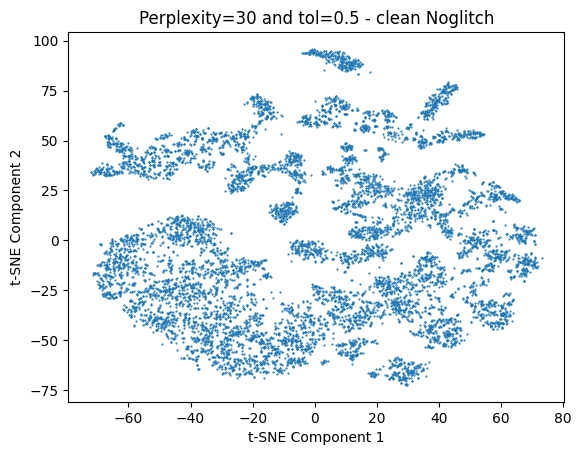

In [291]:
sc = plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f"Perplexity=30 and tol=0.5 - clean Noglitch", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.show()

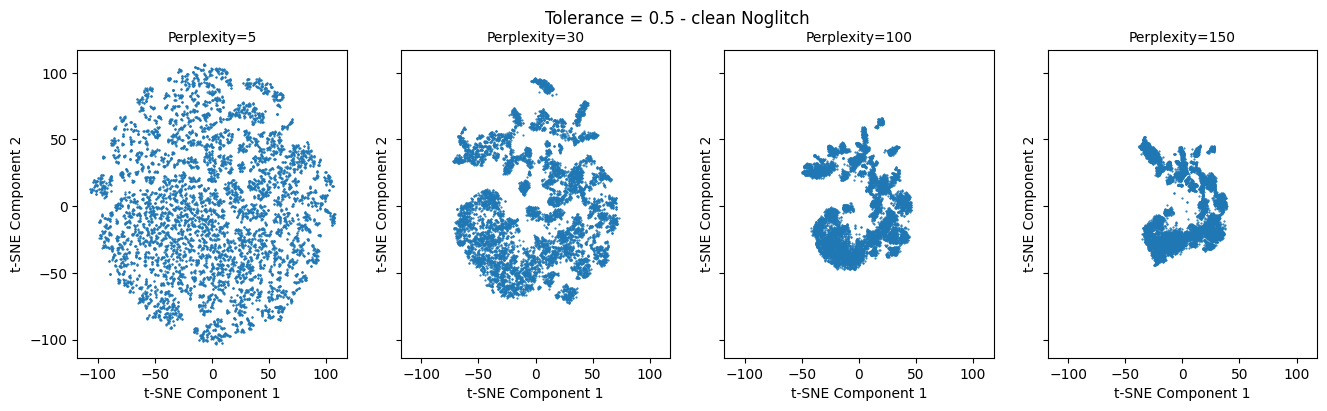

In [292]:
perplexities = [5, 30, 100, 150]

fig, axs = plt.subplots(1, len(perplexities), figsize=(4 * len(perplexities), 4), sharex=True, sharey=True)

for i, perp in enumerate(perplexities):

    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
    proj = tsne.fit_transform(final_vecs)

    ax = axs[i]
    
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3)
    
    ax.set_title(f"Perplexity={perp}", fontsize=10)
    ax.set_xlabel("t-SNE Component 1", fontsize=10)
    ax.set_ylabel("t-SNE Component 2", fontsize=10)

fig.suptitle(f"Tolerance = 0.5 - clean Noglitch", fontsize=12)
    
plt.show()

### HDBSCAN*

In [294]:
perp = 30

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

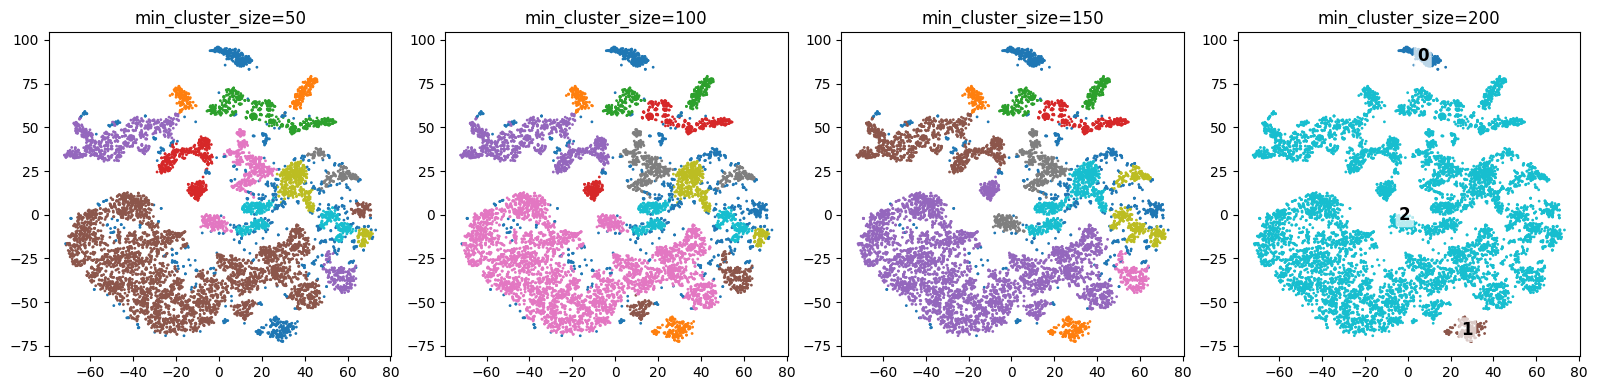

In [307]:
sizes = [50, 100, 150, 200]

fig, axs = plt.subplots(1, len(sizes), figsize=(len(sizes)*4, 4))

for i, s in enumerate(sizes):
    hdbscan_labels = HDBSCAN(min_cluster_size=s, min_samples=20).fit_predict(proj)

    axs[i].scatter(*proj.T, c=hdbscan_labels, cmap='tab10', s=1)
    axs[i].set_title(f'min_cluster_size={s}', fontsize=12)

    if s == 200:
        unique_labels = np.unique(hdbscan_labels)
        clusters_validos = [lbl for lbl in unique_labels if lbl >= 0]
        
        for lbl in clusters_validos:
            pontos_cluster = proj[hdbscan_labels == lbl]
            
            centroide_x = np.mean(pontos_cluster[:, 0])
            centroide_y = np.mean(pontos_cluster[:, 1])
            
            axs[i].text(
                centroide_x, centroide_y, str(lbl),
                fontsize=12, fontweight='bold', color='black',
                ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
            )
            
plt.tight_layout()
plt.show()

### Temporal Analysis

In [276]:
data = pd.read_csv(save_file + "/" + arqType + suffix + ".csv")

data_sample = data.sample(n=10000, random_state=0)
clustered = data_sample.sort_values(by='time').reset_index(drop=True)

In [284]:
perp = 100
min_cluster_size = 200
min_samples = 200

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

hdbscan_labels = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples).fit_predict(proj)

In [285]:
valid_clusters = [lbl for lbl in np.unique(hdbscan_labels) if lbl >= 0]

In [286]:
valid_clusters

[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

In [287]:
dfs_clusters = {}

for lbl in valid_clusters:
    mask = (hdbscan_labels == lbl)

    dfs_clusters[lbl] = clustered[mask].copy()

    print(f"Cluster {lbl}: {len(dfs_clusters[lbl])} elementos")

ValueError: Item wrong length 50000 instead of 10000.

## Glitchgrams

In [173]:
start_day_O3a = datetime(2019, 7, 1, 3, 50, 0)
end_day_O3a   = datetime(2019, 7, 28, 7, 20, 0)

t_inicio_gps = Time(start_day_O3a, scale="utc").gps
t_fim_gps   = Time(end_day_O3a, scale="utc").gps

data_inicio = Time(t_inicio_gps, format='gps').utc.iso
data_fim = Time(t_fim_gps, format='gps').utc.iso

print(f'from {data_inicio} to {data_fim}')

from 2019-07-01 03:50:00.000 to 2019-07-28 07:20:00.000


In [214]:
filter_clusters = {}

for i, content in enumerate(dfs_clusters.items()):
    
    content = dfs_clusters[i]
    content = content[(content['time'] >= t_inicio_gps) & (content['time'] <= t_fim_gps)]
    
    filter_clusters[i] = content

In [242]:
df = filter_clusters[3]

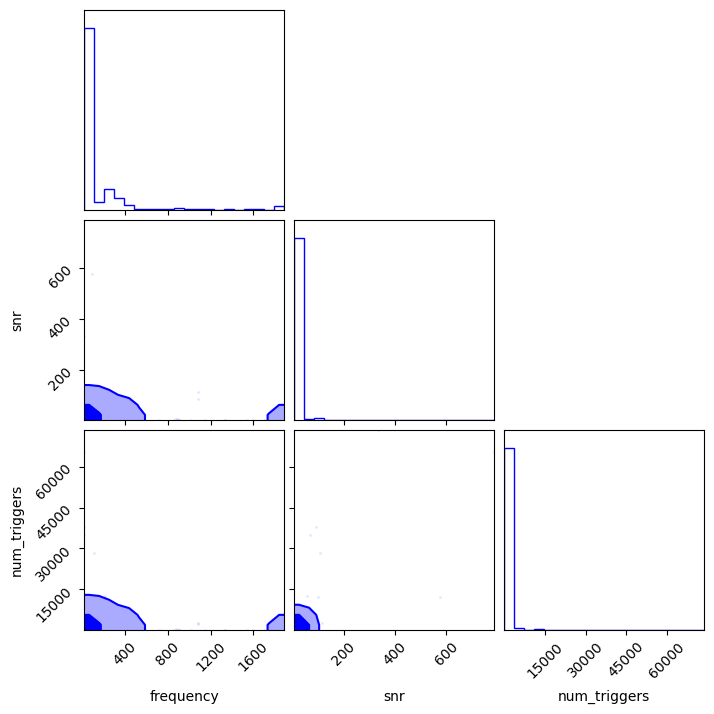

In [243]:
# 2. Convertendo as colunas do DataFrame para um array do NumPy (que o corner consome)
df_log = pd.DataFrame({
    'log_frequency': df['frequency'] + 1,
    'log_snr': df['snr'] + 1,
    'log_num_triggers': df['num_triggers'] + 1
})

# 3. Definindo os rótulos correspondentes para os eixos
labels = ['frequency', 'snr', 'num_triggers']

# 4. Gerando o Corner Plot
fig = corner.corner(
    df_log,
    labels=labels,
    color='blue',           # Cor dos contornos e linhas
    plot_contours=True,     # Desenha as elipses de contorno
    fill_contours=True,     # Preenche o interior dos contornos com cor translúcida
    levels=(0.68, 0.95),    # Níveis de confiança padrão (1-sigma e 2-sigma)
    smooth=1.0,             # Suavização das curvas
    hist_kwargs={'density': True}
)

plt.show()

In [207]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# 1. Selecionar as colunas e aplicar o log (já que vimos que melhora a distribuição)
features = ['frequency', 'snr', 'num_triggers']
X_raw = np.log10(data[features] + 1)

# 2. Normalizar os dados (Média = 0, Desvio Padrão = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 3. Aplicar o Gaussian Mixture Model (GMM)
# Você pode definir o número de clusters (ex: n_components=4 baseado nos grupos que você encontrou antes)
n_clusters = 4
gmm = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42)
cluster_labels = gmm.fit_predict(X_scaled)

# 4. Adicionar os rótulos de volta ao DataFrame original
data['cluster_param_gmm'] = cluster_labels

Centros dos clusters (espaço normalizado):
 [[ 1.296185   -0.38890483 -0.47207234]
 [-0.63216987 -0.24400324 -0.32866255]
 [ 0.94139375  2.2447182   2.50208341]
 [-0.43994376  0.23423527  0.41261306]]


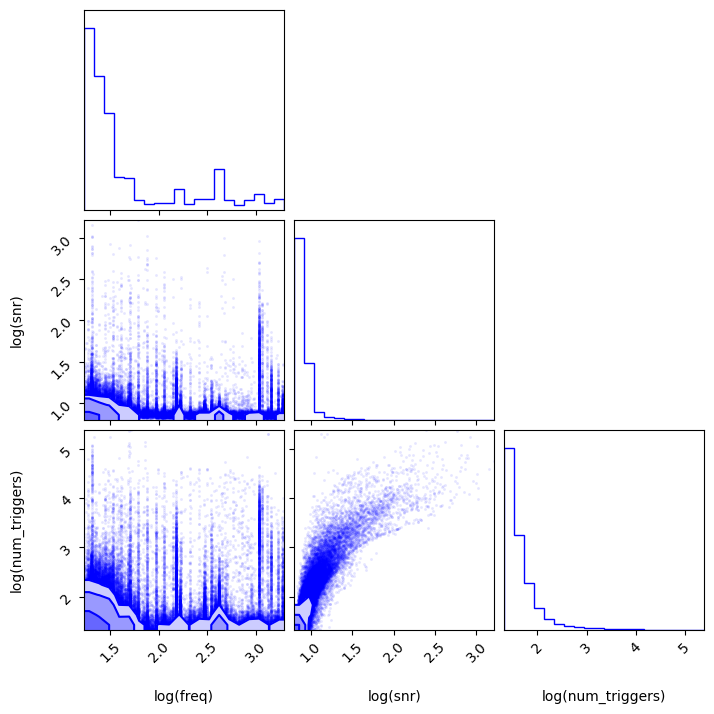

In [208]:
import corner
import matplotlib.pyplot as plt

# Convertendo para array
dados_array = X_raw.values

# Gerando o corner plot com os pontos coloridos pelos clusters do GMM
fig = corner.corner(
    dados_array,
    labels=['log(freq)', 'log(snr)', 'log(num_triggers)'],
    color='blue',
    plot_contours=True,
    fill_contours=True
)

# Opcional: Se quiser sobrescrever ou ajustar a visualização para destacar os grupos,
# você pode inspecionar os centros dos clusters obtidos pelo GMM:
print("Centros dos clusters (espaço normalizado):\n", gmm.means_)

In [174]:
unclustered = unclustered_all[(unclustered_all["time"] >= t_inicio_gps) & (unclustered_all["time"] <= t_fim_gps)].sort_values("time").reset_index(drop=True)

NameError: name 'unclustered_all' is not defined

### cluster 0 ~ orange

In [73]:
cluster = 0

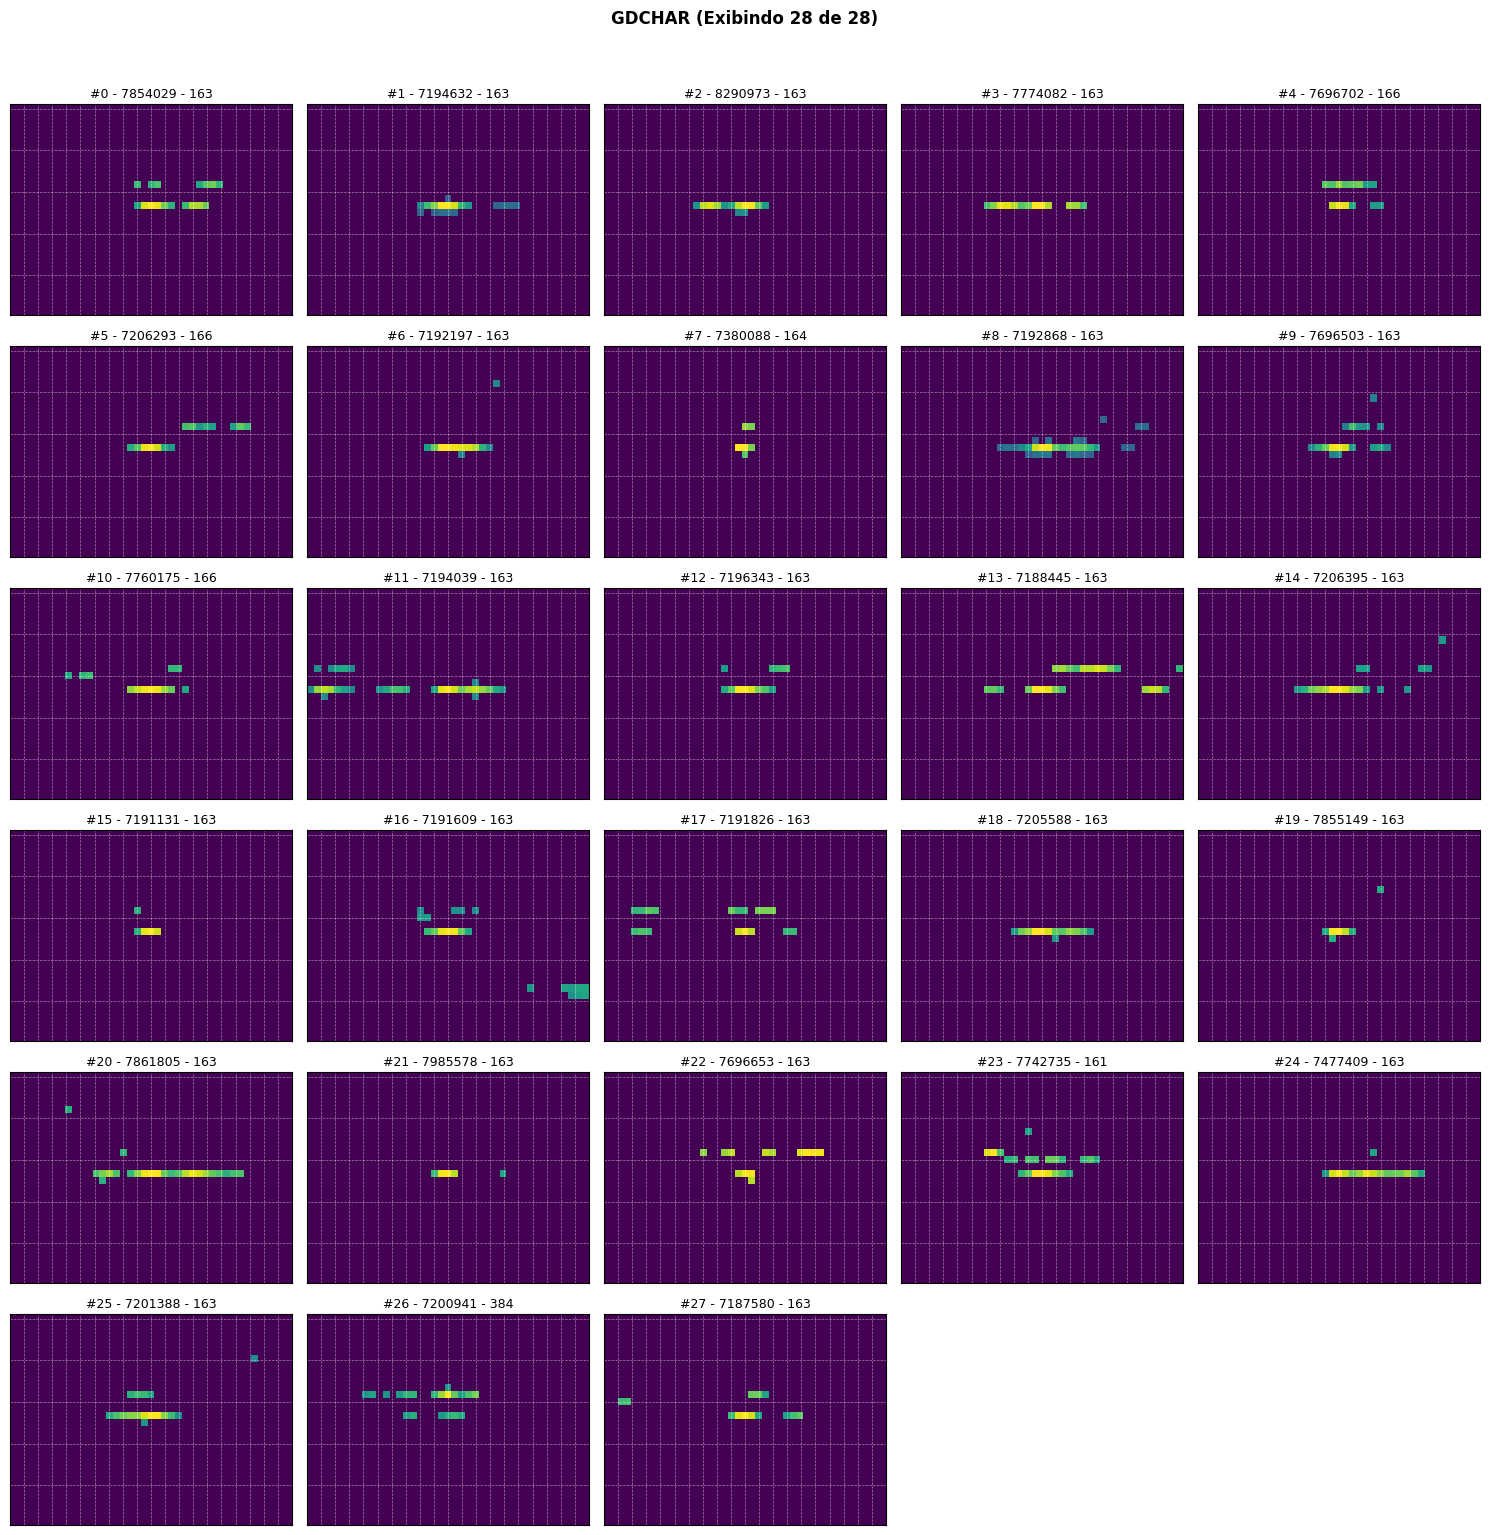

In [74]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

### cluster 1 ~ red

In [76]:
cluster = 1

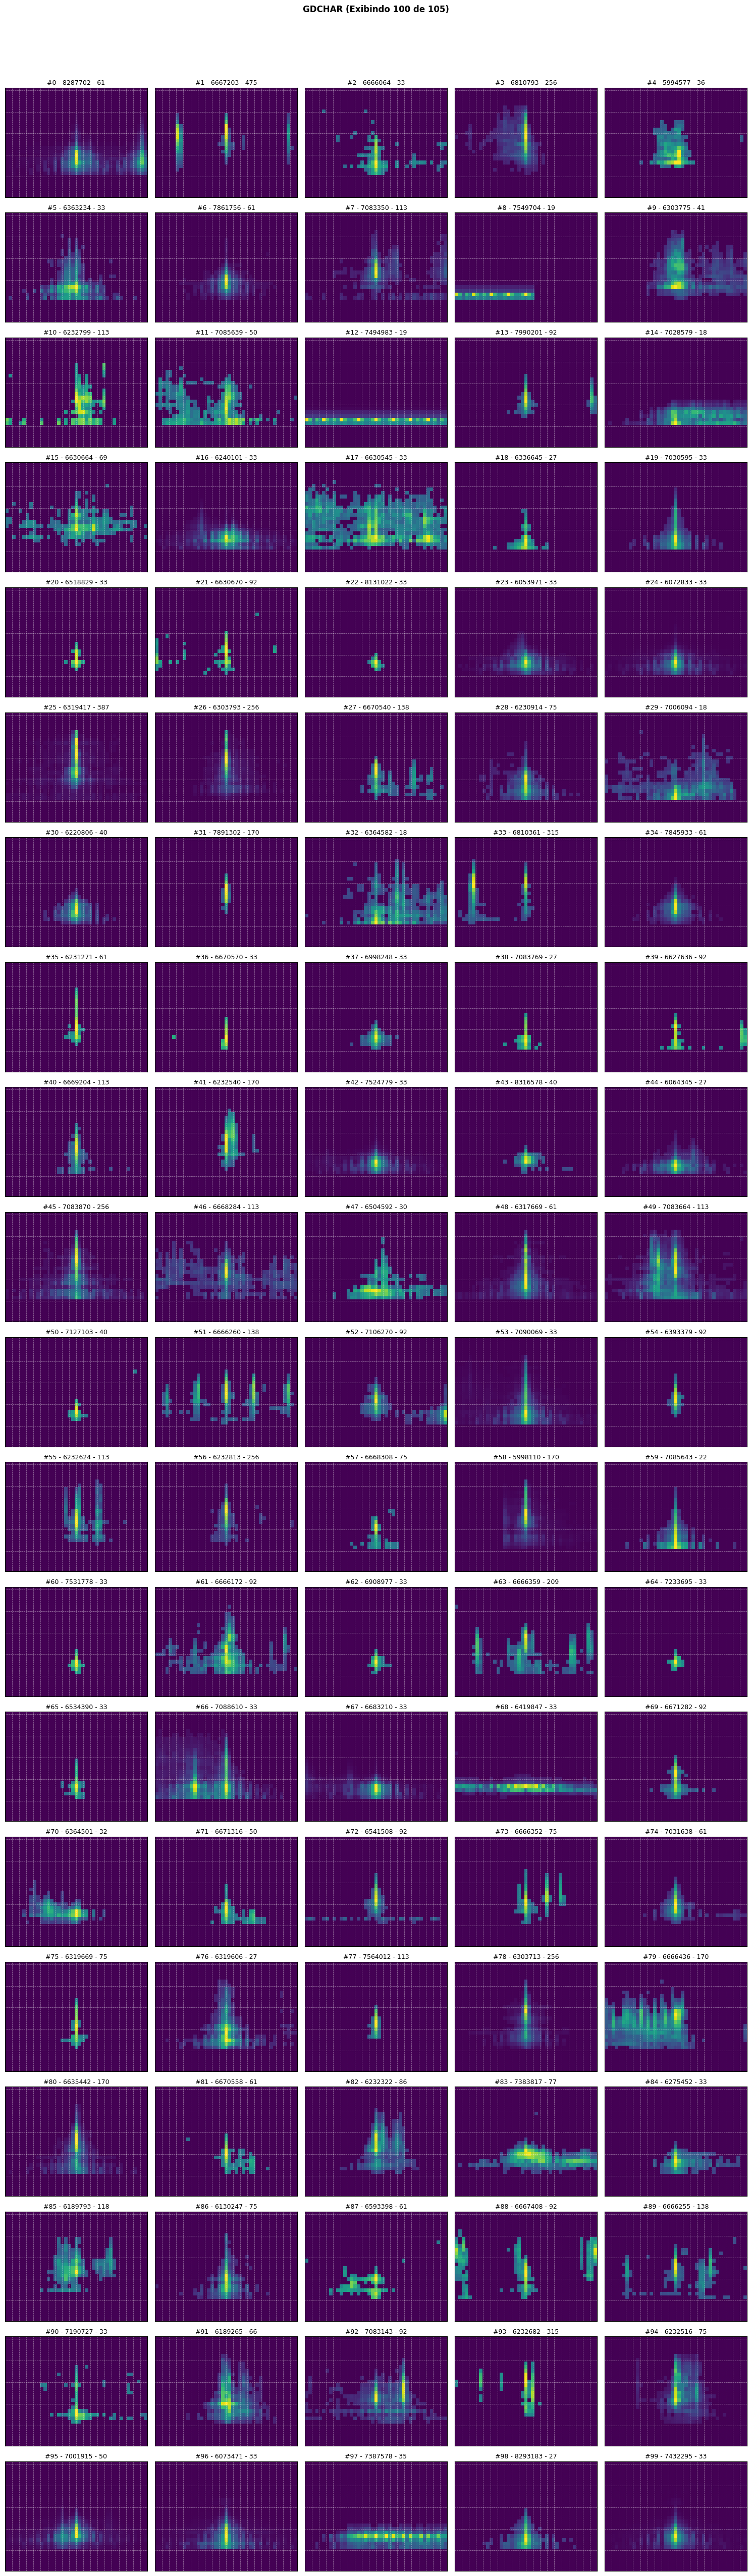

In [77]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

### cluster 2 ~ brown

In [78]:
cluster = 2

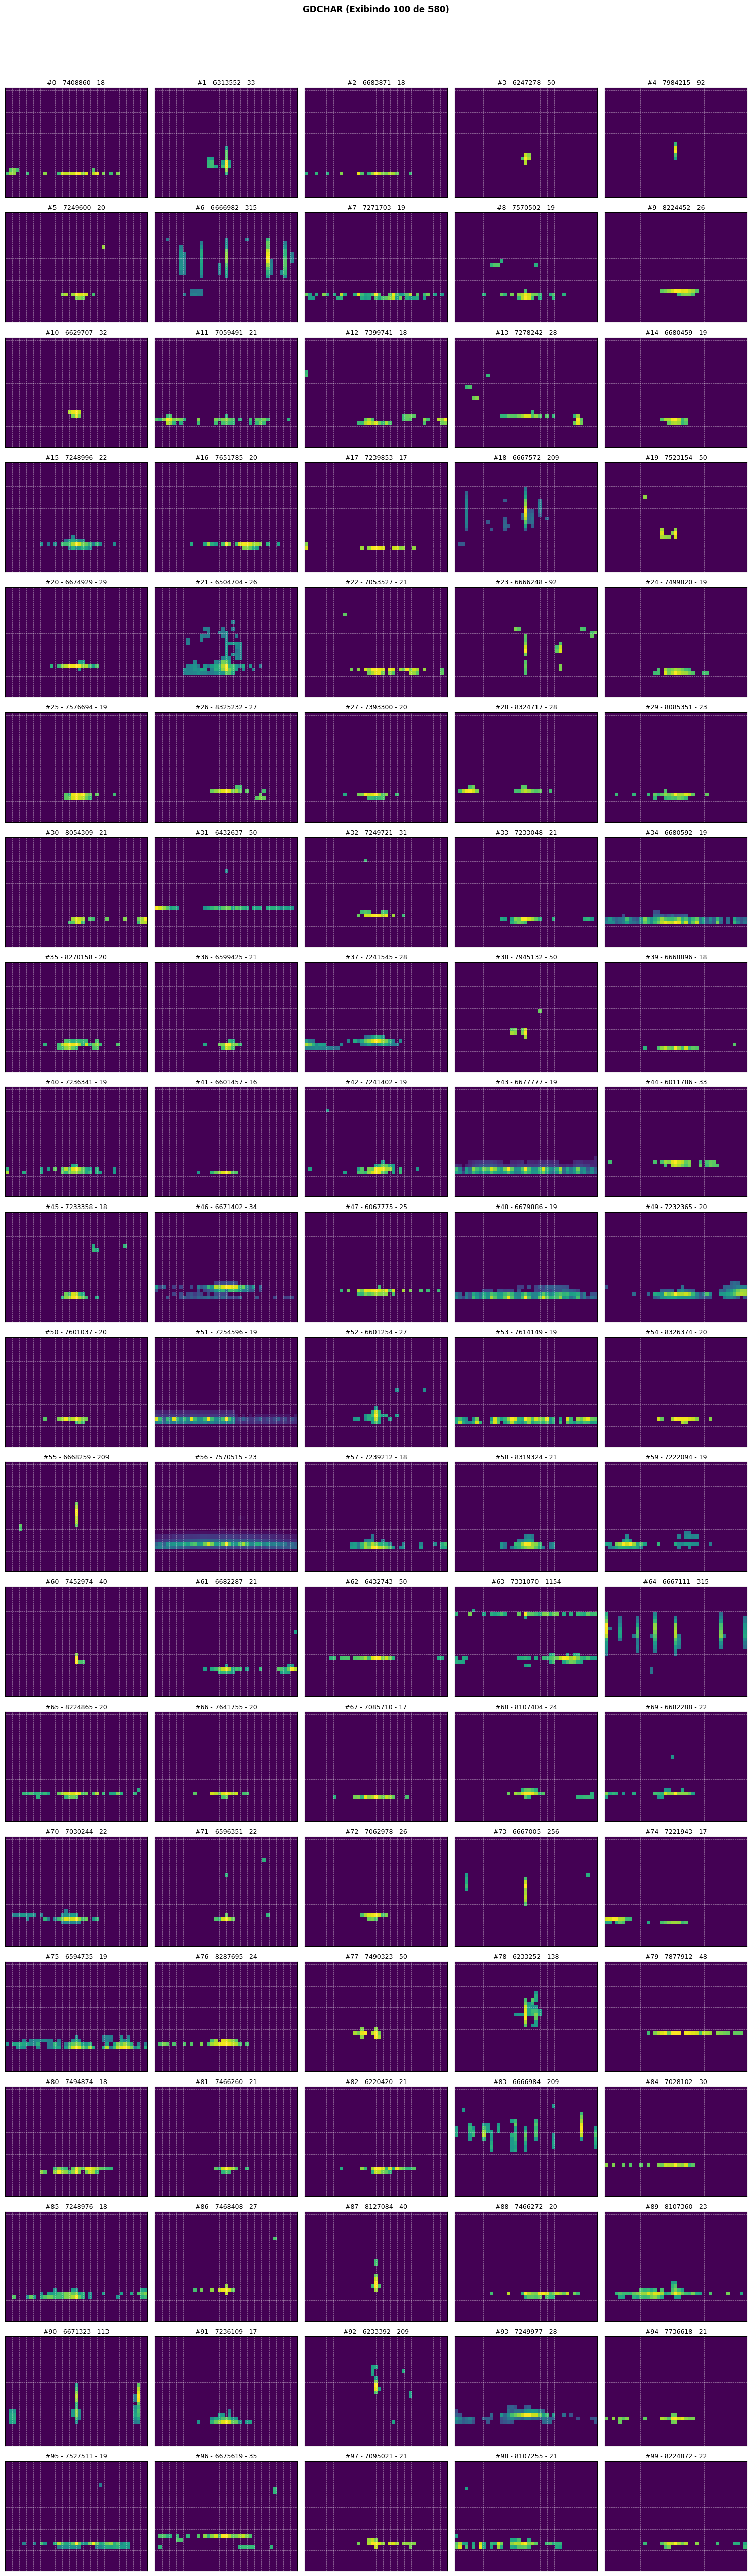

In [79]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

### cluster 3 ~ pink

In [80]:
cluster = 3

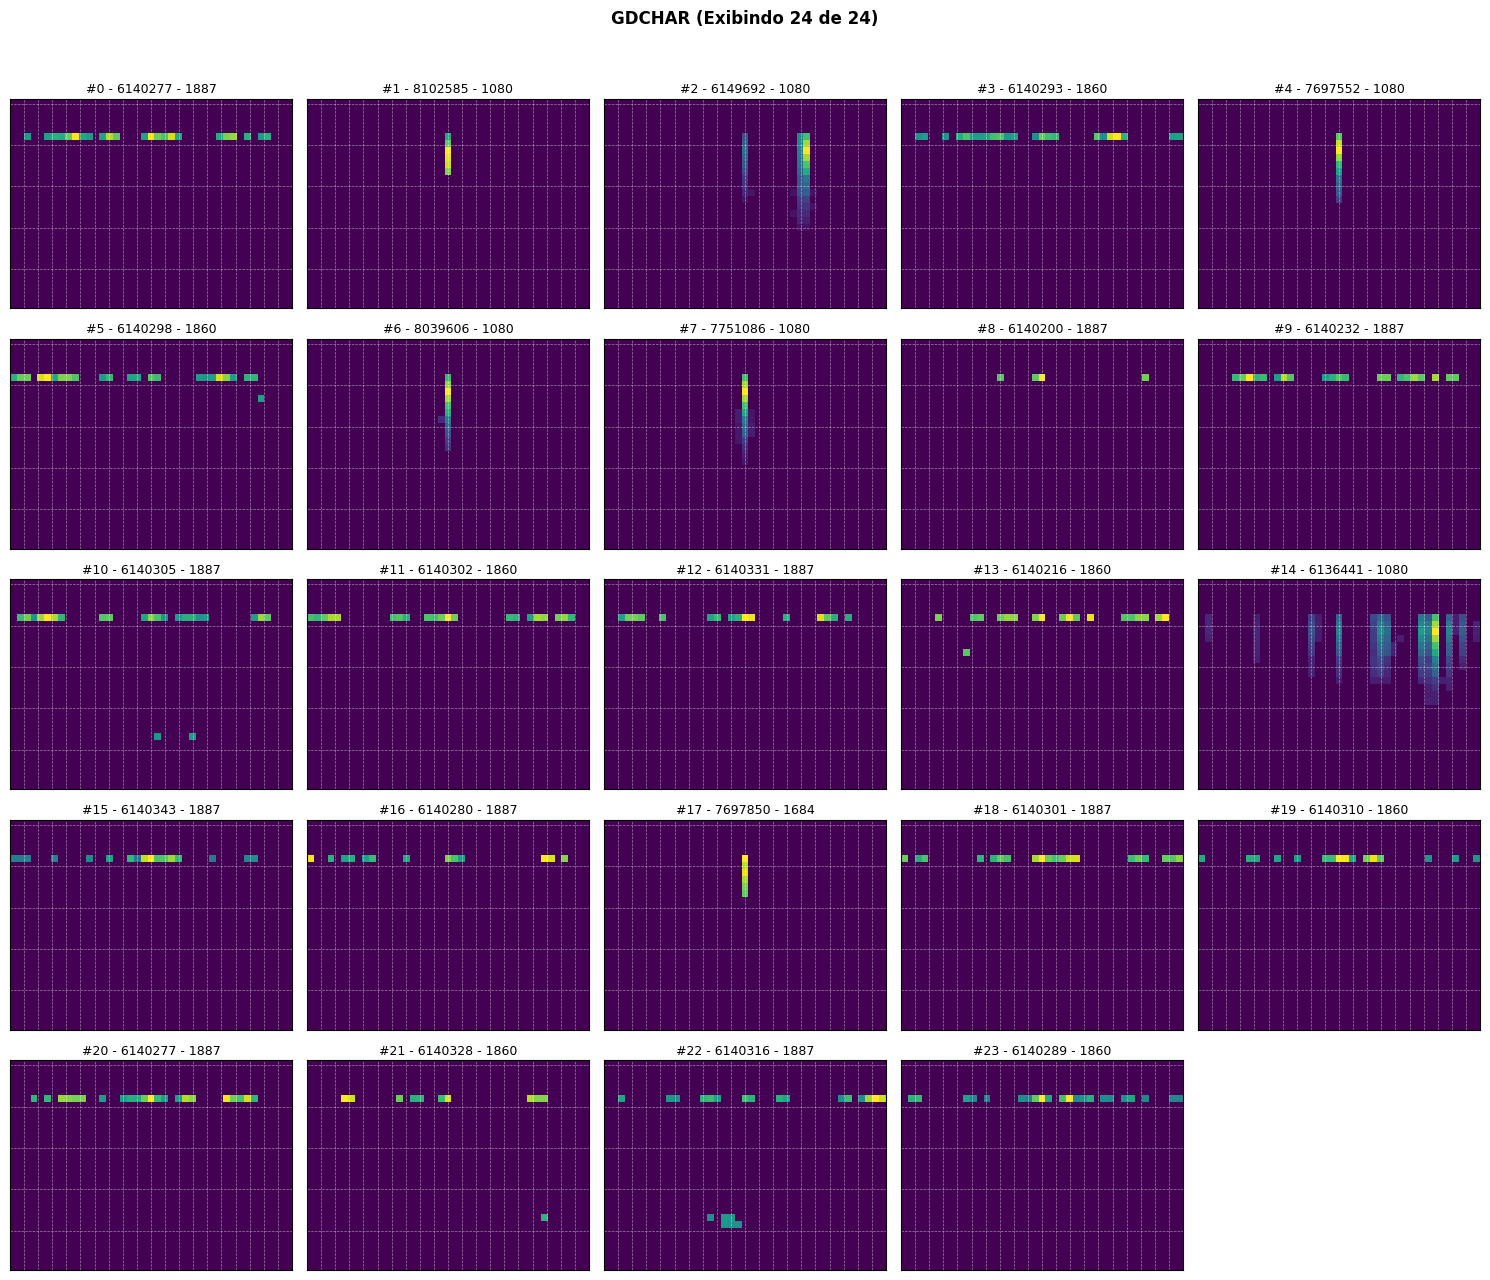

In [81]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

### cluster 4 ~ yellow

In [82]:
cluster = 4

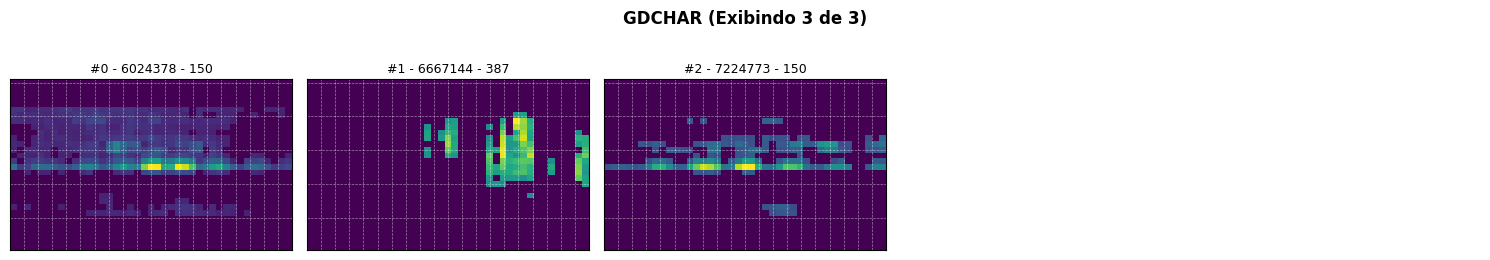

In [83]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

### cluster 5 ~ lightblue

In [84]:
cluster = 5

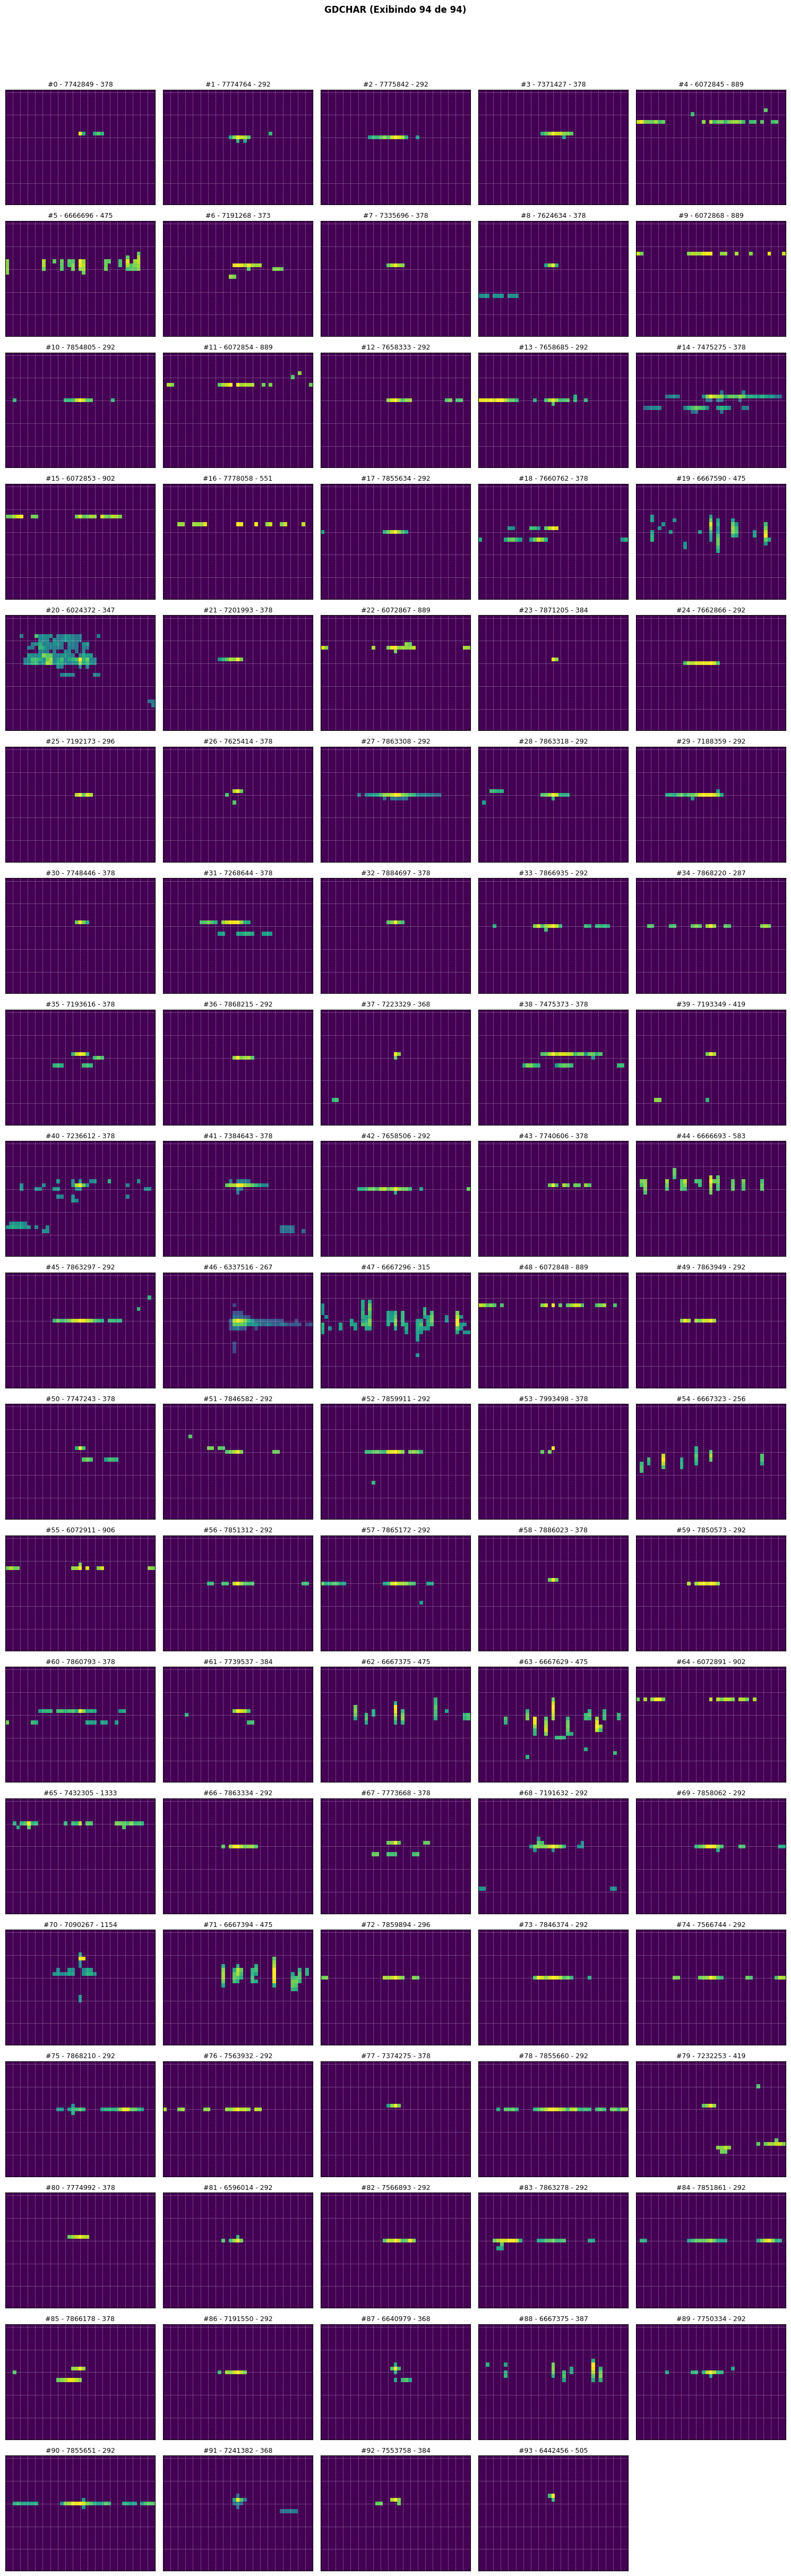

In [85]:
arquive = os.path.join(vectors_path, f"gdchar_cluster_{cluster}_mcs_{mcs}.csv")
cluster = pd.read_csv(arquive)

cluster = cluster[(cluster['time'] >= t_inicio_gps) & (cluster['time'] <= t_fim_gps)]
matrices_gspy, times_gspy, freqs_gspy = create_glitchgram(unclustered, cluster, deltat)

plot_grid2(matrices_gspy, times_gspy, freqs_gspy, 'GDCHAR', 100)

////////////////////////////////////////////////////////////////

In [45]:
repository

'/home/esanches/Projetos/tSNE/Virgo/zrepository/gdchar/O3b/'

In [46]:
prefixos = ['vecs', 'labs', 'GPSs']

carregados = {}

for prefixo in prefixos:

    nome_arquivo = f"{prefixo}{sufixo}{cut}.npy"
    caminho_final = os.path.join(repository, nome_arquivo)

    if os.path.exists(caminho_final):
        carregados[f"final_{prefixo}"] = np.load(caminho_final)

final_vecs = carregados.get('final_vecs')
final_labs = carregados.get('final_labs')
final_GPSs = carregados.get('final_GPSs')

In [47]:
len(final_vecs)

10000

O3a tSNE from our clustering

In [48]:
tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=30, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

////////////////////////////////////////////////

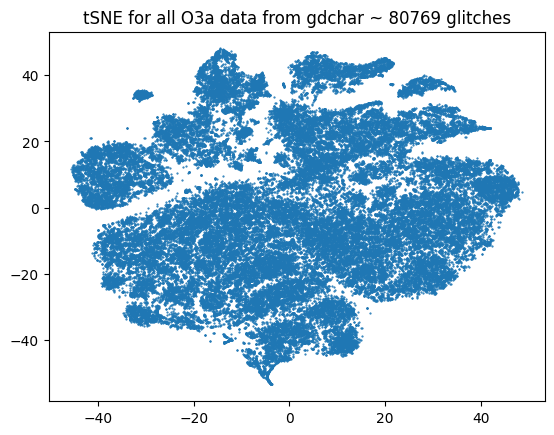

In [24]:
plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f'tSNE for all O3a data from gdchar ~ {len(final_vecs)} glitches')
plt.show()

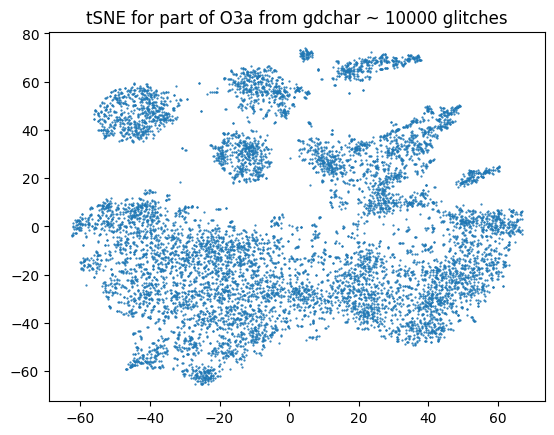

In [31]:
plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f'tSNE for part of O3a from gdchar ~ {len(final_vecs)} glitches')
plt.show()

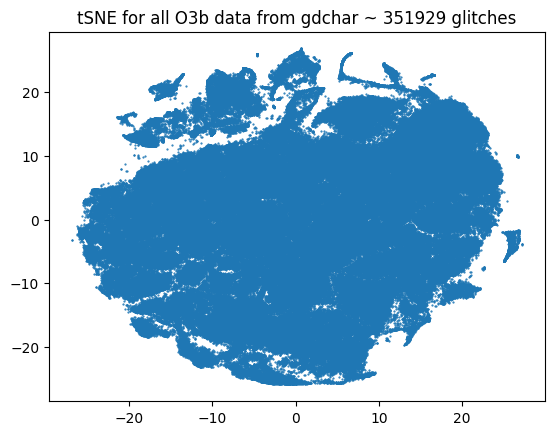

In [38]:
plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f'tSNE for all O3b data from gdchar ~ {len(final_vecs)} glitches')
plt.show()

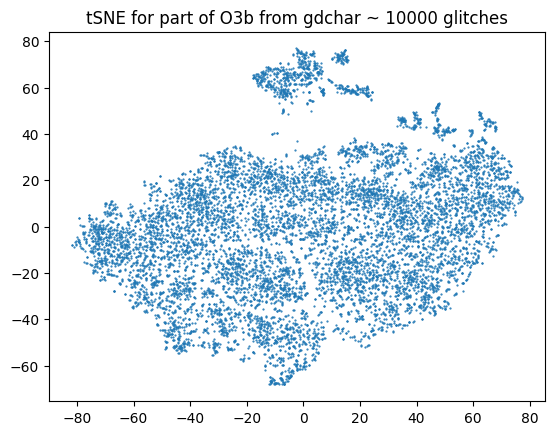

In [49]:
plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f'tSNE for part of O3b from gdchar ~ {len(final_vecs)} glitches')
plt.show()

KeyboardInterrupt: 

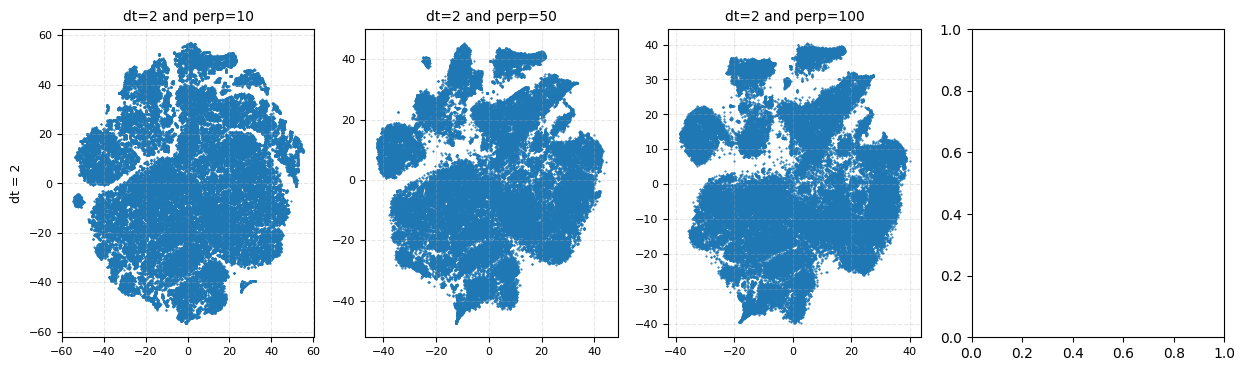

In [14]:
lista_perp = [10, 50, 100, 250]

fig, axs = plt.subplots(1, 4, figsize=(15, 4))

le = LabelEncoder()
# final_labs = np.load(labels_repository + 'gspy/O3a/labs_gspyO3a_dt2.npy')
labels = le.fit_transform(final_labs.ravel())

# final_vecs = np.load(f"{repository}vecs_{arq_name}_dt{str(dt)}.npy")

for j, perp in enumerate(lista_perp):
    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
    proj = tsne.fit_transform(final_vecs)

    ax = axs[j]
    # sc = ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3)
    ax.set_title(f"dt={dt} and perp={perp}", fontsize=10)
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.grid(True, linestyle="--", alpha=0.3)
    
    if j == 0:
        ax.set_ylabel(f"dt = {dt}", fontsize=9)

# fig.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), title="Glitches", loc='center left', bbox_to_anchor=(0.89, 0.5))
plt.show()

In [21]:
dt = 2
perp = 100

# final_vecs = np.load(f"{repository}vecs_{arq_name}_dt{str(dt)}.npy")
# final_labs = np.load(f"{repository}labs_{arq_name}_dt{str(dt)}.npy")

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, 
            learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

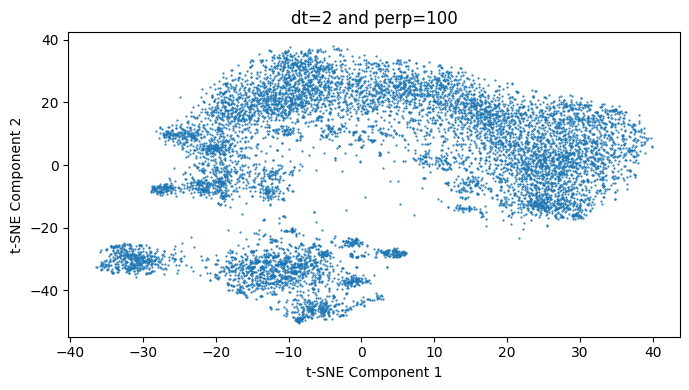

In [22]:
plt.figure(figsize=(7, 4))

sc = plt.scatter(proj[:, 0], proj[:, 1], s=0.3)

plt.title(f"dt={dt} and perp={perp}", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.tight_layout()
plt.show()

In [4]:
dt, perp = 2, 100

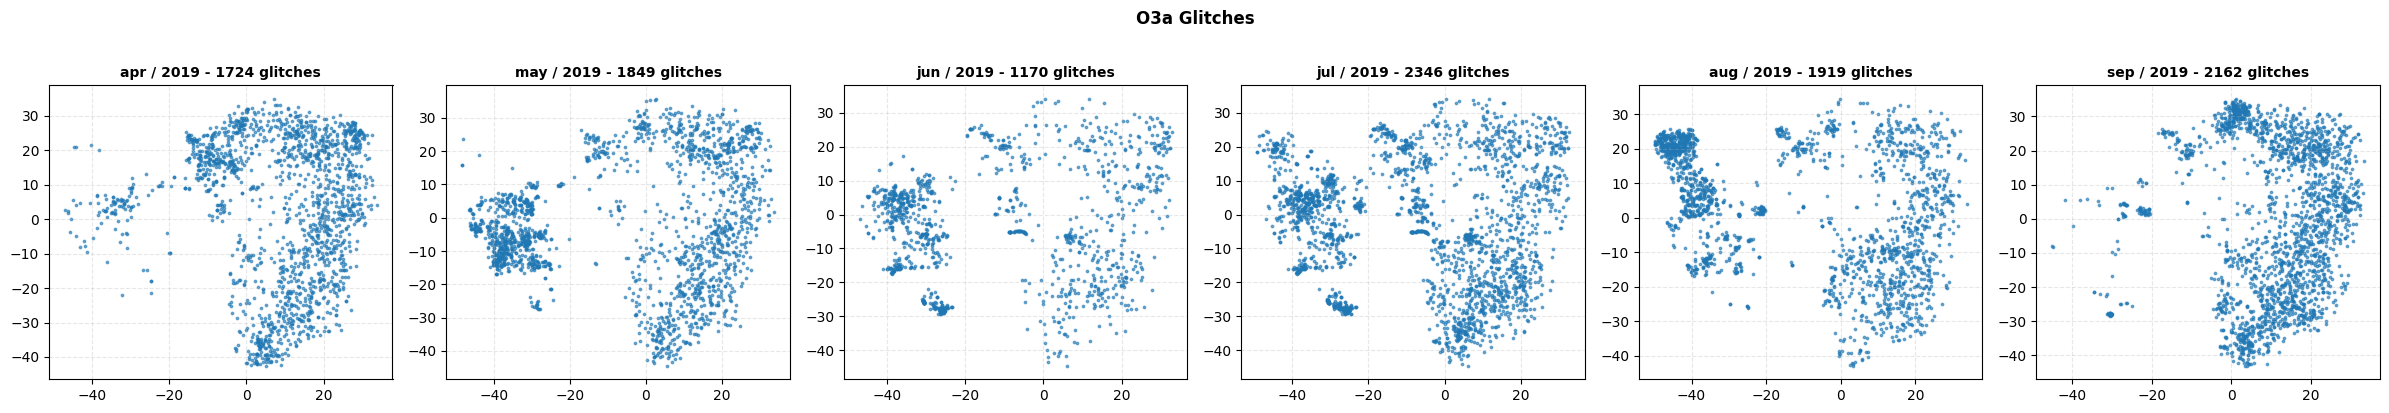

In [6]:
o3a_intervals = {
    'Apr': (1238166018, 1240761618),
    'May': (1240761618, 1243440018),
    'Jun': (1243440018, 1246032018),
    'Jul': (1243440018, 1248710418),
    'Aug': (1248710418, 1251388818),
    'Sep': (1251388818, 1253980818)
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_intervals)
gf.plot_saz(projs, 'O3a Glitches', color='C0')

O3b tSNE from our clustering

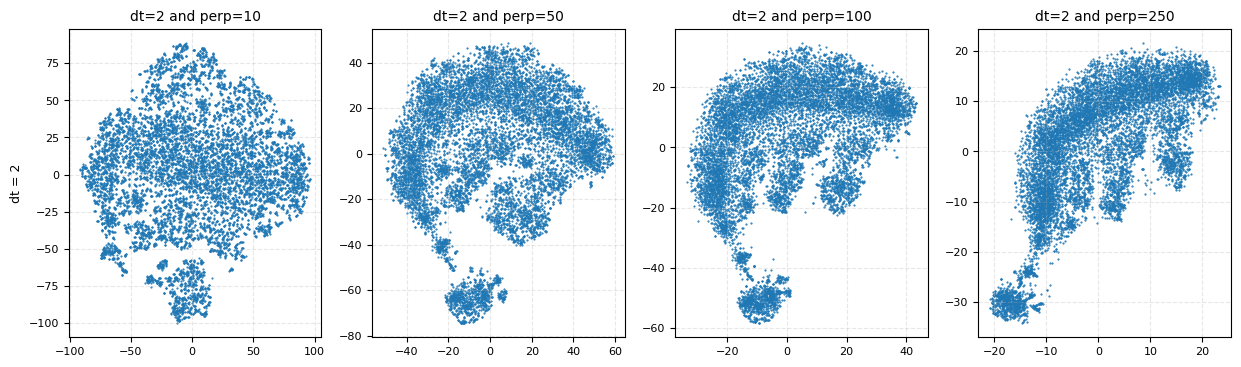

In [6]:
lista_perp = [10, 50, 100, 250]

fig, axs = plt.subplots(1, 4, figsize=(15, 4))

le = LabelEncoder()
# final_labs = np.load(labels_repository + 'gspy/O3a/labs_gspyO3a_dt2.npy')
labels = le.fit_transform(final_labs.ravel())

# final_vecs = np.load(f"{repository}vecs_{arq_name}_dt{str(dt)}.npy")

for j, perp in enumerate(lista_perp):
    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=0)
    proj = tsne.fit_transform(final_vecs)

    ax = axs[j]
    # sc = ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3)
    ax.set_title(f"dt={dt} and perp={perp}", fontsize=10)
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.grid(True, linestyle="--", alpha=0.3)
    
    if j == 0:
        ax.set_ylabel(f"dt = {dt}", fontsize=9)

# fig.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), title="Glitches", loc='center left', bbox_to_anchor=(0.89, 0.5))
plt.show()